# **E-commerce Sales and Operations Intelligence**

## Project Overview

This project analyzes the Brazilian E-Commerce Public Dataset by Olist to understand e-commerce sales performance, product category performance, delivery reliability, and customer satisfaction.

Using Python and pandas, the analysis explores sales patterns, delivery delays, regional differences, and the relationship between delivery performance and customer review scores.

### Business Objectives

- Evaluate overall sales performance and identify leading product categories.
- Measure delivery times and assess late-delivery rates.
- Investigate the relationship between delivery delays and customer satisfaction.
- Identify Brazilian states and purchase months with elevated late-delivery rates.
- Translate the findings into actionable business recommendations.

### Key Business Questions

1. Which product categories generate the highest product sales value?
2. How long do customers typically wait for their orders?
3. How frequently do orders arrive later than estimated?
4. Are late deliveries associated with lower customer review scores?
5. Which states and purchase months have higher late-delivery rates?
6. What operational areas should the business investigate to improve the customer experience?

### Tools and Technologies

- Python
- pandas
- Matplotlib
- Seaborn
- Google Colab

### Dataset

The analysis uses the Brazilian E-Commerce Public Dataset by Olist, which contains information about orders, customers, products, payments, reviews, and deliveries.**bold text**

# 1. Import Libraries and Load Data

This section imports the Python libraries required for data analysis and loads the Olist datasets into pandas DataFrames.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [3]:
import zipfile
import os

zip_file = next(iter(uploaded))

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("olist_data")

print("Dataset extracted successfully!")
print(os.listdir("olist_data"))

Dataset extracted successfully!
['olist_products_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_geolocation_dataset.csv', 'product_category_name_translation.csv', 'olist_customers_dataset.csv', 'olist_sellers_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_order_items_dataset.csv']


# 2. Data Understanding

This section explores the structure and contents of the datasets to understand the available information before performing detailed analysis.

The analysis examines:
- Dataset dimensions and column names.
- Data types and general structure.
- Missing values and duplicate records.
- The relationships between orders, products, customers, and reviews.

In [4]:
import pandas as pd
import os

data_path = "olist_data"

orders = pd.read_csv(os.path.join(data_path, "olist_orders_dataset.csv"))
order_items = pd.read_csv(os.path.join(data_path, "olist_order_items_dataset.csv"))
products = pd.read_csv(os.path.join(data_path, "olist_products_dataset.csv"))

print("ORDERS DATASET")
print("Shape:", orders.shape)
display(orders.head())

print("\nORDER ITEMS DATASET")
print("Shape:", order_items.shape)
display(order_items.head())

print("\nPRODUCTS DATASET")
print("Shape:", products.shape)
display(products.head())

ORDERS DATASET
Shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



ORDER ITEMS DATASET
Shape: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



PRODUCTS DATASET
Shape: (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [5]:
# 1. Check missing values
print("MISSING VALUES")
print("\nOrders:")
print(orders.isnull().sum())

print("\nOrder Items:")
print(order_items.isnull().sum())

print("\nProducts:")
print(products.isnull().sum())


# 2. Check data types
print("\n\nDATA TYPES")
print("\nOrders:")
print(orders.dtypes)

print("\nOrder Items:")
print(order_items.dtypes)

print("\nProducts:")
print(products.dtypes)


# 3. Check duplicate records
print("\n\nDUPLICATE ROWS")
print("Orders:", orders.duplicated().sum())
print("Order items:", order_items.duplicated().sum())
print("Products:", products.duplicated().sum())

MISSING VALUES

Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Order Items:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Products:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


DATA TYPES

Orders:
order_id                         object
customer_id                      object
order_status             

# 3. Data Cleaning and Quality Checks

This section checks the quality and consistency of the datasets before analysis.

The following tasks are performed:
- Convert relevant date columns into datetime format.
- Identify missing values and duplicate records.
- Examine missing values in the context of order statuses.
- Prepare the datasets for reliable sales and delivery analysis.

In [6]:
# Convert order timestamps to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

# Convert the shipping deadline to datetime
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

print("Timestamp conversion completed!")

print("\nUpdated order data types:")
print(orders[date_columns].dtypes)

print("\nPurchase date range:")
print("Start:", orders["order_purchase_timestamp"].min())
print("End:", orders["order_purchase_timestamp"].max())

Timestamp conversion completed!

Updated order data types:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Purchase date range:
Start: 2016-09-04 21:15:19
End: 2018-10-17 17:30:18


In [7]:
# Count orders by status
print("ORDER STATUS DISTRIBUTION")

display(
    orders["order_status"]
    .value_counts(dropna=False)
    .rename_axis("order_status")
    .reset_index(name="order_count")
)

# Check missing delivery dates by order status
print("\nMISSING CUSTOMER DELIVERY DATES BY STATUS")

display(
    orders.groupby("order_status")["order_delivered_customer_date"]
    .agg(
        total_orders="size",
        missing_delivery_dates=lambda x: x.isna().sum()
    )
    .reset_index()
)

ORDER STATUS DISTRIBUTION


,order_status,order_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2



MISSING CUSTOMER DELIVERY DATES BY STATUS


,order_status,total_orders,missing_delivery_dates
0,approved,2,2
1,canceled,625,619
2,created,5,5
3,delivered,96478,8
4,invoiced,314,314
5,processing,301,301
6,shipped,1107,1107
7,unavailable,609,609


# 4. Sales Performance Analysis

This section evaluates the platform's overall sales performance using order and order-item data.

The analysis includes:
- Total orders, delivered orders, and canceled orders.
- Product sales value and shipping charges.
- Monthly product sales trends.
- Monthly order volumes and average sales value per order.

The objective is to establish a sales baseline and identify notable trends in business performance.

In [8]:
# 1. Calculate order-level metrics
total_orders = orders["order_id"].nunique()

delivered_orders = orders.loc[
    orders["order_status"] == "delivered",
    "order_id"
].nunique()

canceled_orders = orders.loc[
    orders["order_status"] == "canceled",
    "order_id"
].nunique()

# 2. Calculate order-item metrics
total_order_items = len(order_items)

all_item_sales = order_items["price"].sum()
all_shipping_charges = order_items["freight_value"].sum()

# 3. Calculate delivered-order sales
delivered_order_ids = orders.loc[
    orders["order_status"] == "delivered",
    "order_id"
]

delivered_items = order_items[
    order_items["order_id"].isin(delivered_order_ids)
]

delivered_item_sales = delivered_items["price"].sum()
delivered_shipping_charges = delivered_items["freight_value"].sum()

# 4. Display results
print("BASELINE BUSINESS METRICS")
print("-" * 35)

print(f"Total orders: {total_orders:,}")
print(f"Delivered orders: {delivered_orders:,}")
print(f"Canceled orders: {canceled_orders:,}")
print(f"Total order-item rows: {total_order_items:,}")

print("\nALL ORDER ITEMS")
print(f"Product sales value: R$ {all_item_sales:,.2f}")
print(f"Shipping charges: R$ {all_shipping_charges:,.2f}")

print("\nITEMS ASSOCIATED WITH DELIVERED ORDERS")
print(f"Product sales value: R$ {delivered_item_sales:,.2f}")
print(f"Shipping charges: R$ {delivered_shipping_charges:,.2f}")

BASELINE BUSINESS METRICS
-----------------------------------
Total orders: 99,441
Delivered orders: 96,478
Canceled orders: 625
Total order-item rows: 112,650

ALL ORDER ITEMS
Product sales value: R$ 13,591,643.70
Shipping charges: R$ 2,251,909.54

ITEMS ASSOCIATED WITH DELIVERED ORDERS
Product sales value: R$ 13,221,498.11
Shipping charges: R$ 2,198,275.64


,purchase_month,product_sales_value
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


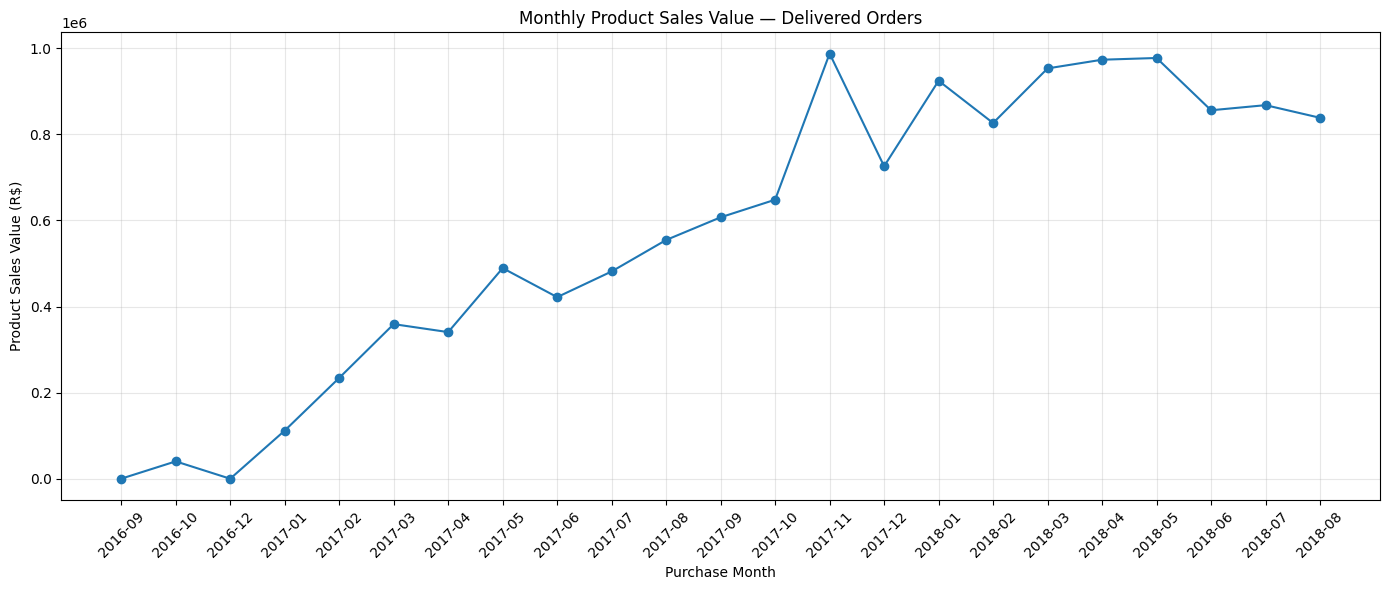

In [9]:
# 1. Select delivered orders and their purchase dates
delivered_orders_data = orders.loc[
    orders["order_status"] == "delivered",
    ["order_id", "order_purchase_timestamp"]
].copy()

# 2. Add purchase month
delivered_orders_data["purchase_month"] = (
    delivered_orders_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# 3. Join order dates with individual order items
monthly_data = delivered_orders_data.merge(
    order_items[["order_id", "price"]],
    on="order_id",
    how="inner"
)

# 4. Calculate monthly product sales value
monthly_sales = (
    monthly_data.groupby("purchase_month")["price"]
    .sum()
    .reset_index()
)

monthly_sales["purchase_month"] = (
    monthly_sales["purchase_month"].astype(str)
)

monthly_sales = monthly_sales.rename(
    columns={"price": "product_sales_value"}
)

# 5. Display the results
display(monthly_sales)

# 6. Plot the monthly trend
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["product_sales_value"],
    marker="o"
)

plt.title("Monthly Product Sales Value — Delivered Orders")
plt.xlabel("Purchase Month")
plt.ylabel("Product Sales Value (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,purchase_month,product_sales_value,delivered_order_count,average_sales_per_order
0,2016-09,134.97,1,134.970000
1,2016-10,40325.11,265,152.170226
2,2016-12,10.90,1,10.900000
3,2017-01,111798.36,750,149.064480
4,2017-02,234223.40,1653,141.695947
5,2017-03,359198.85,2546,141.083602
6,2017-04,340669.68,2303,147.924307
7,2017-05,489338.25,3546,137.997250
8,2017-06,421923.37,3135,134.584807
9,2017-07,481604.52,3872,124.381333


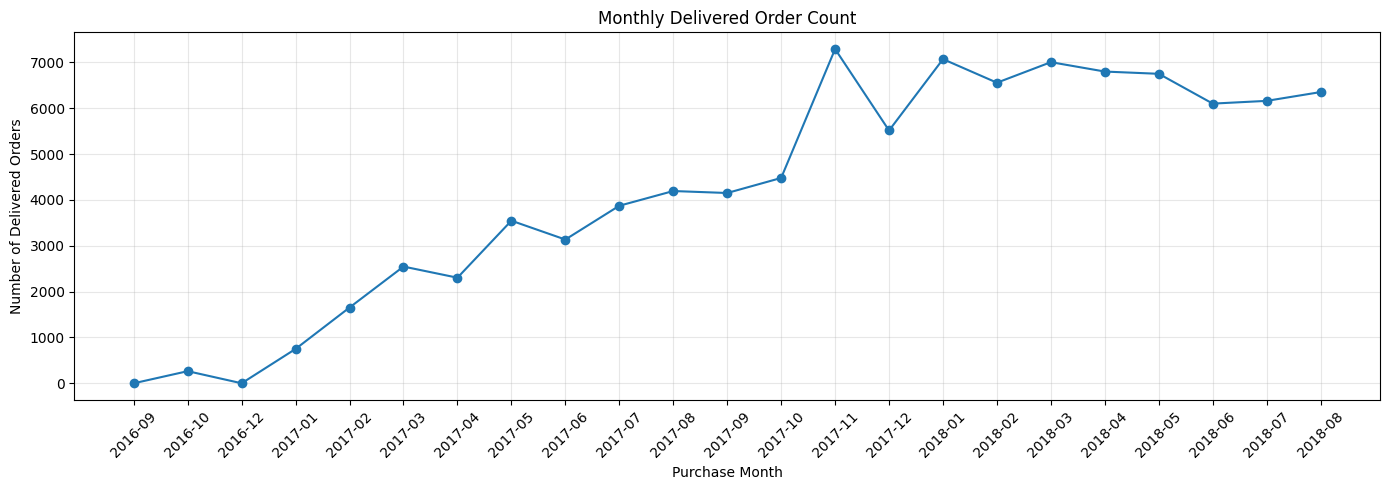

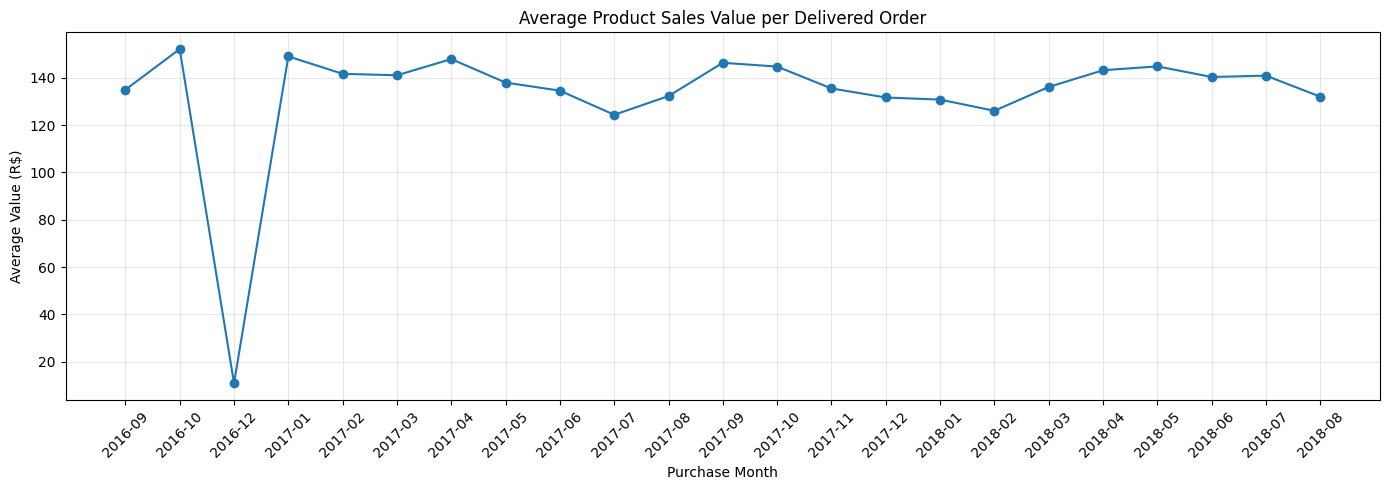

In [10]:
# 1. Count unique delivered orders by purchase month
monthly_order_counts = (
    delivered_orders_data
    .groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="delivered_order_count")
)

# 2. Calculate average product sales value per delivered order
monthly_sales_analysis = monthly_sales.copy()

monthly_sales_analysis["purchase_month"] = pd.PeriodIndex(
    monthly_sales_analysis["purchase_month"],
    freq="M"
)

monthly_sales_analysis = monthly_sales_analysis.merge(
    monthly_order_counts,
    on="purchase_month",
    how="left"
)

monthly_sales_analysis["average_sales_per_order"] = (
    monthly_sales_analysis["product_sales_value"]
    / monthly_sales_analysis["delivered_order_count"]
)

# 3. Format the month for display
monthly_sales_analysis["purchase_month"] = (
    monthly_sales_analysis["purchase_month"].astype(str)
)

display(monthly_sales_analysis)

# 4. Plot monthly delivered order counts
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales_analysis["purchase_month"],
    monthly_sales_analysis["delivered_order_count"],
    marker="o"
)

plt.title("Monthly Delivered Order Count")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Delivered Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Plot average sales value per delivered order
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales_analysis["purchase_month"],
    monthly_sales_analysis["average_sales_per_order"],
    marker="o"
)

plt.title("Average Product Sales Value per Delivered Order")
plt.xlabel("Purchase Month")
plt.ylabel("Average Value (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Show monthly order counts and average sales values
# for the months that look unusual.

months_to_check = ["2016-09", "2016-10", "2016-11", "2016-12",
                   "2017-10", "2017-11", "2017-12"]

monthly_check = monthly_sales_analysis[
    monthly_sales_analysis["purchase_month"].isin(months_to_check)
].copy()

display(monthly_check)

# Count all orders by purchase month, regardless of status
orders["purchase_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

all_monthly_orders = (
    orders.groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="all_order_count")
)

all_monthly_orders["purchase_month"] = (
    all_monthly_orders["purchase_month"].astype(str)
)

print("All order counts for the months being investigated:")

display(
    all_monthly_orders[
        all_monthly_orders["purchase_month"].isin(months_to_check)
    ]
)

,purchase_month,product_sales_value,delivered_order_count,average_sales_per_order
0,2016-09,134.97,1,134.970000
1,2016-10,40325.11,265,152.170226
2,2016-12,10.90,1,10.900000
12,2017-10,648247.65,4478,144.762762
13,2017-11,987765.37,7289,135.514525
14,2017-12,726033.19,5513,131.694756


All order counts for the months being investigated:


,purchase_month,all_order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
12,2017-10,4631
13,2017-11,7544
14,2017-12,5673


In [12]:
# Load the English product category translations
category_translation = pd.read_csv(
    os.path.join(data_path, "product_category_name_translation.csv")
)

print("Category translation dataset:")
print("Shape:", category_translation.shape)

display(category_translation.head())

Category translation dataset:
Shape: (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


# 5. Product Category Analysis

This section examines product sales performance across different categories using orders that were successfully delivered.

The analysis includes:
- Translating product category names into English.
- Calculating product sales value by category.
- Comparing the number of items sold and unique orders across categories.
- Identifying the top 10 product categories by sales value.
- Visualizing category performance to identify leading contributors.

The objective is to understand which product categories contribute most to the platform's product sales value.

In [13]:

# 1. Select delivered orders
delivered_order_ids = orders.loc[
    orders["order_status"] == "delivered",
    "order_id"
]

# 2. Keep items belonging to delivered orders
delivered_items = order_items[
    order_items["order_id"].isin(delivered_order_ids)
].copy()

# 3. Add product categories
category_data = delivered_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# 4. Translate category names into English
category_data = category_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# 5. Label missing or untranslated categories
category_data["product_category_name_english"] = (
    category_data["product_category_name_english"]
    .fillna("Unknown / Untranslated")
)

# 6. Calculate category-level metrics
category_sales = (
    category_data.groupby("product_category_name_english")
    .agg(
        product_sales_value=("price", "sum"),
        items_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("product_sales_value", ascending=False)
)

# 7. Display the top 10 categories
top_10_categories = category_sales.head(10)

display(top_10_categories)


,product_category_name_english,product_sales_value,items_sold,unique_orders
44,health_beauty,1233131.72,9465,8647
71,watches_gifts,1166176.98,5859,5495
8,bed_bath_table,1023434.76,10953,9272
66,sports_leisure,954852.55,8431,7530
16,computers_accessories,888724.61,7644,6530
40,furniture_decor,711927.69,8160,6307
50,housewares,615628.69,6795,5743
21,cool_stuff,610204.10,3718,3559
6,auto,578966.65,4140,3810
70,toys,471286.48,4030,3804


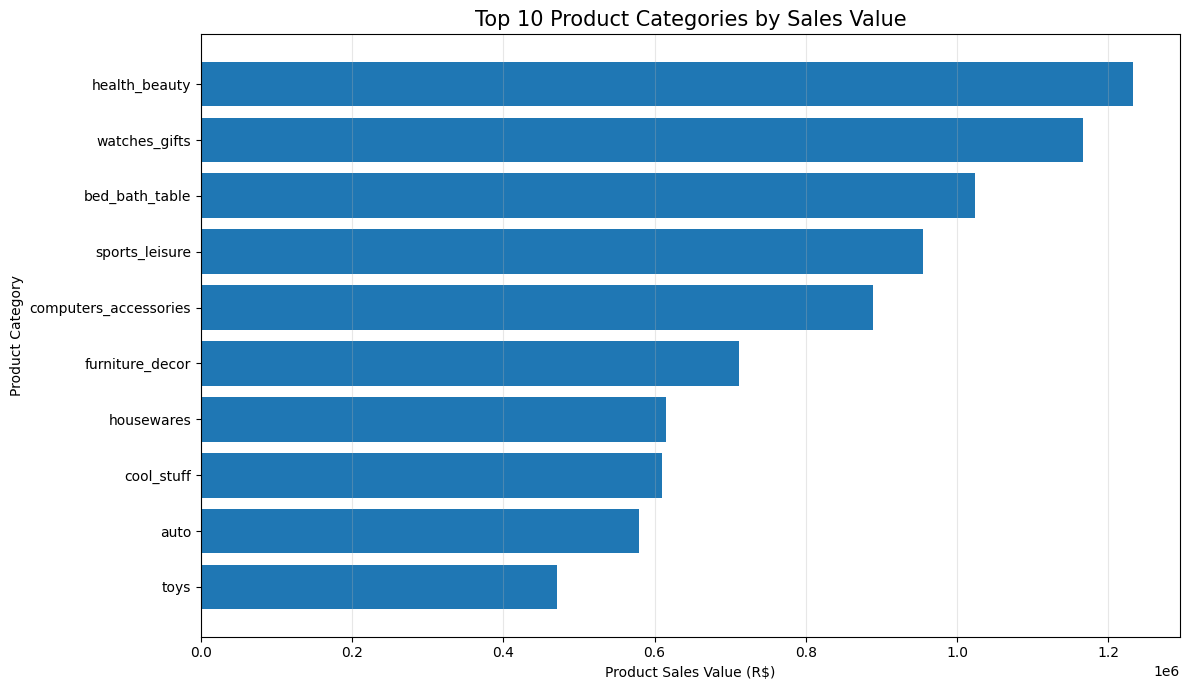

In [14]:
# Sort categories for a readable horizontal bar chart
plot_data = top_10_categories.sort_values(
    "product_sales_value",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["product_category_name_english"],
    plot_data["product_sales_value"]
)

plt.title(
    "Top 10 Product Categories by Sales Value",
    fontsize=15
)

plt.xlabel("Product Sales Value (R$)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Delivery Performance Analysis

This section evaluates how reliably the platform delivers orders to customers.

The analysis includes:
- Calculating delivery duration from purchase to customer delivery.
- Comparing actual delivery dates with estimated delivery dates.
- Measuring the proportion of orders delivered late versus on time or early.
- Examining the severity of late deliveries.
- Exploring delivery performance across product categories.

The objective is to identify delivery delays and highlight areas that may require further operational investigation.

In [15]:
# Keep only delivered orders with valid purchase and delivery dates
delivery_data = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notna()) &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calculate delivery time in days
delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"] -
    delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Display summary statistics
print("Delivery Time Summary (Days)")
print("-----------------------------")
print(delivery_data["delivery_days"].describe().round(2))

Delivery Time Summary (Days)
-----------------------------
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_days, dtype: float64


In [16]:
# Keep orders with actual and estimated delivery dates
delay_data = delivery_data[
    delivery_data["order_estimated_delivery_date"].notna()
].copy()

# Calculate delay in days
delay_data["delay_days"] = (
    delay_data["order_delivered_customer_date"] -
    delay_data["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Classify orders as late or not late
delay_data["delivery_result"] = delay_data["delay_days"].apply(
    lambda days: "Late" if days > 0 else "On time or early"
)

# Summarize delivery performance
delivery_summary = (
    delay_data["delivery_result"]
    .value_counts()
    .rename_axis("delivery_result")
    .reset_index(name="order_count")
)

delivery_summary["percentage"] = (
    delivery_summary["order_count"] /
    delivery_summary["order_count"].sum() * 100
).round(2)

display(delivery_summary)

,delivery_result,order_count,percentage
0,On time or early,88644,91.89
1,Late,7826,8.11


In [17]:
# Select only orders delivered after the estimated date
late_orders = delay_data[
    delay_data["delay_days"] > 0
].copy()

# Summarize the severity of late deliveries
print("Late Delivery Analysis")
print("----------------------")
print(late_orders["delay_days"].describe().round(2))

Late Delivery Analysis
----------------------
count    7826.00
mean        9.55
std        13.95
min         0.00
25%         1.87
50%         5.81
75%        11.82
max       188.98
Name: delay_days, dtype: float64


In [18]:
# Add product categories to the delivery data
delivery_category_data = delay_data.merge(
    order_items[["order_id", "product_id"]],
    on="order_id",
    how="left"
)

delivery_category_data = delivery_category_data.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

delivery_category_data = delivery_category_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Label orders according to delivery performance
delivery_category_data["is_late"] = (
    delivery_category_data["delay_days"] > 0
)

# Calculate delivery performance by category
category_delivery = (
    delivery_category_data
    .groupby("product_category_name_english")
    .agg(
        total_items=("order_id", "count"),
        late_items=("is_late", "sum"),
        avg_delay_days=("delay_days", "mean")
    )
    .reset_index()
)

category_delivery["late_rate_pct"] = (
    category_delivery["late_items"] /
    category_delivery["total_items"] * 100
).round(2)

# Show categories with the highest late-delivery rates
top_late_categories = (
    category_delivery[
        category_delivery["total_items"] >= 100
    ]
    .sort_values("late_rate_pct", ascending=False)
    .head(10)
)

display(top_late_categories)

,product_category_name_english,total_items,late_items,avg_delay_days,late_rate_pct
4,audio,362,46,-9.466330,12.71
33,fashion_underwear_beach,127,16,-10.210535,12.60
12,christmas_supplies,150,18,-11.328950,12.00
10,books_technical,263,29,-10.601557,11.03
47,home_confort,429,44,-9.114846,10.26
18,construction_tools_lights,301,30,-10.507701,9.97
36,food,499,49,-9.179071,9.82
26,electronics,2729,266,-10.434594,9.75
43,health_beauty,9465,857,-11.267750,9.05
57,office_furniture,1668,149,-11.153240,8.93


In [19]:
# Keep only category-associated records that were delivered late
late_category_data = delivery_category_data[
    delivery_category_data["delay_days"] > 0
].copy()

# Calculate performance among late records for each category
late_category_summary = (
    late_category_data
    .groupby("product_category_name_english")
    .agg(
        late_items=("order_id", "count"),
        avg_delay_days=("delay_days", "mean"),
        median_delay_days=("delay_days", "median")
    )
    .reset_index()
)

# Sort by average delay, from highest to lowest
late_category_summary = (
    late_category_summary
    .sort_values("avg_delay_days", ascending=False)
)

display(late_category_summary.head(10).round(2))

,product_category_name_english,late_items,avg_delay_days,median_delay_days
43,home_appliances_2,16,19.93,7.41
39,furniture_mattress_and_upholstery,5,15.71,9.02
1,air_conditioning,11,15.12,13.87
52,music,3,12.73,14.88
35,food_drink,17,12.60,3.77
45,home_confort,44,12.47,8.70
44,home_comfort_2,5,12.33,11.89
23,drinks,20,11.99,5.02
58,signaling_and_security,11,11.23,3.67
28,fashion_male_clothing,7,11.12,11.73


# 7. Customer Satisfaction Analysis

This section examines customer review scores and investigates their relationship with delivery performance.

The analysis includes:
- Examining the distribution of customer review scores.
- Checking for multiple review records associated with individual orders.
- Creating an order-level review summary.
- Comparing average customer review scores for late deliveries and orders delivered on time or early.
- Visualizing differences in customer satisfaction between the two delivery groups.

The objective is to understand whether late deliveries are associated with lower customer satisfaction.

In [20]:
# Load the order reviews dataset
reviews = pd.read_csv(
    os.path.join(data_path, "olist_order_reviews_dataset.csv")
)

# Check the dataset structure
print("Reviews dataset shape:", reviews.shape)

display(reviews.head())

Reviews dataset shape: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [21]:
# Check the distribution of review scores
print("Review Score Distribution")
print("-------------------------")

display(
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="review_count")
)

# Check how many orders have multiple review records
print("\nReview Records per Order")
print("------------------------")

print(
    "Total review records:", len(reviews)
)

print(
    "Unique orders reviewed:", reviews["order_id"].nunique()
)

print(
    "Orders with multiple review records:",
    (reviews.groupby("order_id").size() > 1).sum()
)

Review Score Distribution
-------------------------


,review_score,review_count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328



Review Records per Order
------------------------
Total review records: 99224
Unique orders reviewed: 98673
Orders with multiple review records: 547


In [22]:
# Create one review score per order
order_reviews = (
    reviews.groupby("order_id")
    .agg(
        review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    .reset_index()
)

print("Unique orders in review summary:", order_reviews["order_id"].nunique())
print("Total review records represented:", order_reviews["review_count"].sum())

display(order_reviews.head())

Unique orders in review summary: 98673
Total review records represented: 99224


,order_id,review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1
1,00018f77f2f0320c557190d7a144bdd3,4.0,1
2,000229ec398224ef6ca0657da4fc703e,5.0,1
3,00024acbcdf0a6daa1e931b038114c75,4.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1


In [23]:
# Merge delivery performance with customer reviews
delivery_reviews = delay_data.merge(
    order_reviews,
    on="order_id",
    how="inner"
)

print("Orders with both delivery and review data:", len(delivery_reviews))
print("Unique orders in merged dataset:", delivery_reviews["order_id"].nunique())

display(
    delivery_reviews[
        ["order_id", "delivery_days", "delay_days",
         "delivery_result", "review_score"]
    ].head()
)

Orders with both delivery and review data: 95824
Unique orders in merged dataset: 95824


,order_id,delivery_days,delay_days,delivery_result,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488,On time or early,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729,On time or early,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498,On time or early,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069,On time or early,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171,On time or early,5.0


In [24]:
# Compare customer satisfaction by delivery performance

delivery_satisfaction = (
    delivery_reviews
    .groupby("delivery_result")
    .agg(
        total_orders=("order_id", "nunique"),
        avg_review_score=("review_score", "mean"),
        one_star_orders=("review_score", lambda scores: (scores == 1).sum()),
        five_star_orders=("review_score", lambda scores: (scores == 5).sum())
    )
    .reset_index()
)

delivery_satisfaction["one_star_pct"] = (
    delivery_satisfaction["one_star_orders"]
    / delivery_satisfaction["total_orders"] * 100
).round(2)

delivery_satisfaction["five_star_pct"] = (
    delivery_satisfaction["five_star_orders"]
    / delivery_satisfaction["total_orders"] * 100
).round(2)

delivery_satisfaction["avg_review_score"] = (
    delivery_satisfaction["avg_review_score"].round(2)
)

display(delivery_satisfaction)

,delivery_result,total_orders,avg_review_score,one_star_orders,five_star_orders,one_star_pct,five_star_pct
0,Late,7661,2.57,3533,1701,46.12,22.20
1,On time or early,88163,4.29,5779,54996,6.55,62.38


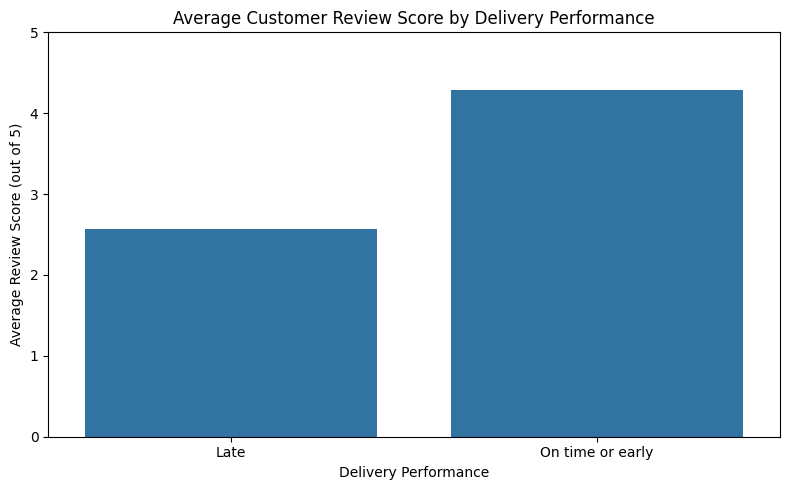

In [25]:
# Compare average customer review scores by delivery performance

plt.figure(figsize=(8, 5))

sns.barplot(
    data=delivery_satisfaction,
    x="delivery_result",
    y="avg_review_score"
)

plt.title("Average Customer Review Score by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [26]:
# Load customer information
customers = pd.read_csv(
    os.path.join(data_path, "olist_customers_dataset.csv")
)

print("Customers dataset shape:", customers.shape)
display(customers.head())

Customers dataset shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


# 8. Regional Delivery Analysis

This section compares delivery performance across Brazilian states using customer location data.

The analysis includes:
- Calculating the number of orders and late deliveries in each state.
- Measuring late-delivery rates by state.
- Identifying states with the highest late-delivery rates.
- Identifying states with the highest absolute numbers of late deliveries.
- Visualizing regional differences in delivery performance.

The objective is to identify regions that may need closer investigation to improve delivery reliability.

In [27]:
# Analyze delivery performance by customer state

# Add customer location information to delivery data
customer_delivery = delay_data.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Calculate delivery performance for each state
state_delivery = (
    customer_delivery
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("delay_days", lambda x: (x > 0).sum()),
        avg_delay_days=("delay_days", "mean")
    )
    .reset_index()
)

# Calculate late-delivery rate
state_delivery["late_rate_pct"] = (
    state_delivery["late_orders"]
    / state_delivery["total_orders"] * 100
).round(2)

# Focus on states with at least 100 orders
state_delivery = (
    state_delivery[state_delivery["total_orders"] >= 100]
    .sort_values("late_rate_pct", ascending=False)
)

display(state_delivery.head(10).round(2))

,customer_state,total_orders,late_orders,avg_delay_days,late_rate_pct
1,AL,397,95,-8.03,23.93
9,MA,717,141,-8.89,19.67
16,PI,476,76,-10.63,15.97
5,CE,1279,196,-10.11,15.32
24,SE,335,51,-9.33,15.22
4,BA,3256,457,-10.10,14.04
18,RJ,12350,1664,-11.05,13.47
26,TO,274,35,-11.44,12.77
13,PA,946,117,-13.39,12.37
7,ES,1995,244,-9.80,12.23


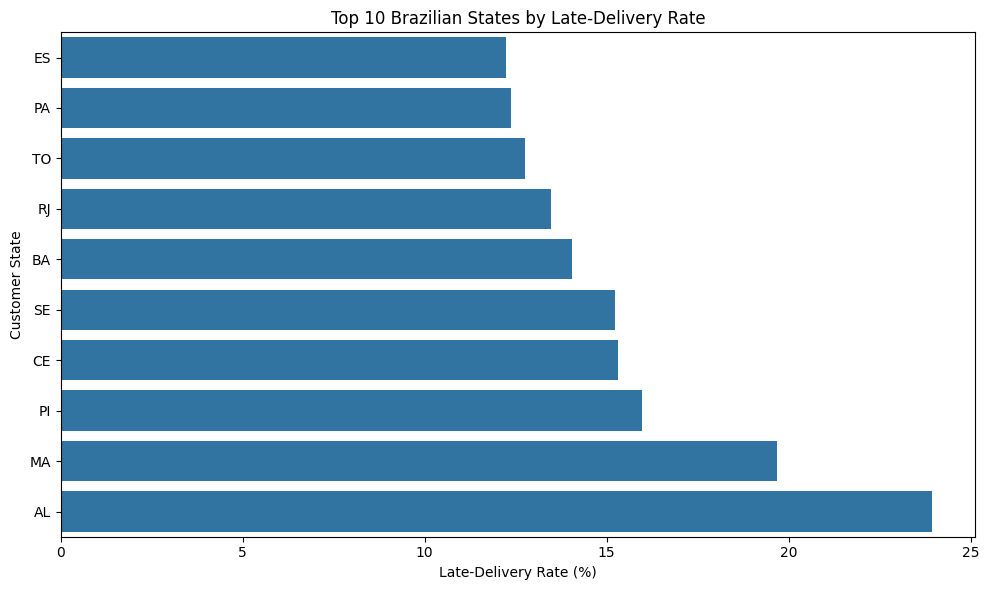

In [28]:
# Visualize the 10 states with the highest late-delivery rates

top_10_late_states = state_delivery.head(10).sort_values(
    "late_rate_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_late_states,
    x="late_rate_pct",
    y="customer_state"
)

plt.title("Top 10 Brazilian States by Late-Delivery Rate")
plt.xlabel("Late-Delivery Rate (%)")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

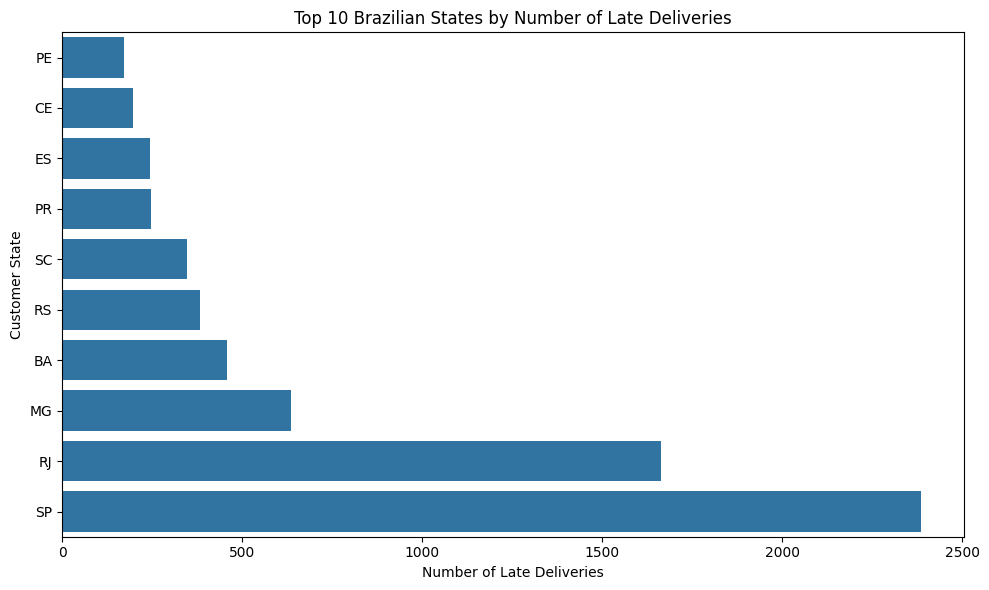

,customer_state,total_orders,late_orders,late_rate_pct
25,SP,40494,2387,5.89
18,RJ,12350,1664,13.47
10,MG,11354,637,5.61
4,BA,3256,457,14.04
22,RS,5344,382,7.15
23,SC,3546,346,9.76
17,PR,4923,246,5.00
7,ES,1995,244,12.23
5,CE,1279,196,15.32
15,PE,1593,172,10.80


In [29]:
# Identify states with the highest number of late deliveries

top_10_late_volume = (
    state_delivery
    .sort_values("late_orders", ascending=False)
    .head(10)
    .sort_values("late_orders", ascending=True)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_late_volume,
    x="late_orders",
    y="customer_state"
)

plt.title("Top 10 Brazilian States by Number of Late Deliveries")
plt.xlabel("Number of Late Deliveries")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

display(
    top_10_late_volume[
        ["customer_state", "total_orders", "late_orders", "late_rate_pct"]
    ].sort_values("late_orders", ascending=False)
)

# 9. Monthly Delivery Trends

This section examines how late-delivery rates vary across purchase months.

The analysis includes:
- Calculating monthly order volumes and late-delivery counts.
- Measuring the late-delivery rate for each purchase month.
- Visualizing changes in delivery performance over time.
- Filtering out months with fewer than 100 eligible orders to reduce the influence of very small samples.

The objective is to identify periods with unusually high late-delivery rates that may warrant further investigation.

In [30]:
# Analyze monthly delivery performance

delay_data["purchase_month"] = (
    delay_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_delivery = (
    delay_data
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("delay_days", lambda x: (x > 0).sum())
    )
    .reset_index()
)

monthly_delivery["late_rate_pct"] = (
    monthly_delivery["late_orders"]
    / monthly_delivery["total_orders"] * 100
).round(2)

display(monthly_delivery.tail(15))

,purchase_month,total_orders,late_orders,late_rate_pct
8,2017-06,3135,121,3.86
9,2017-07,3872,133,3.43
10,2017-08,4193,139,3.32
11,2017-09,4150,216,5.20
12,2017-10,4478,237,5.29
13,2017-11,7288,1043,14.31
14,2017-12,5513,462,8.38
15,2018-01,7069,464,6.56
16,2018-02,6555,1048,15.99
17,2018-03,7003,1496,21.36


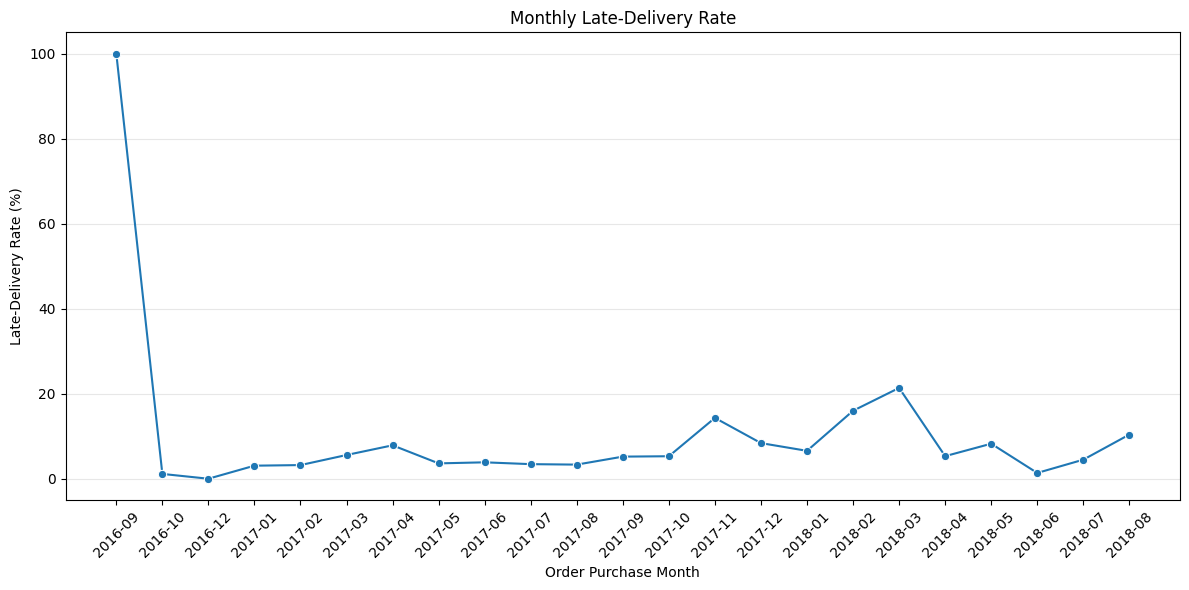

In [31]:
# Visualize monthly late-delivery rates

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_delivery,
    x="purchase_month",
    y="late_rate_pct",
    marker="o"
)

plt.title("Monthly Late-Delivery Rate")
plt.xlabel("Order Purchase Month")
plt.ylabel("Late-Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
# Inspect the earliest months to investigate unusual rates

display(
    monthly_delivery[
        ["purchase_month", "total_orders", "late_orders", "late_rate_pct"]
    ].head(6)
)

,purchase_month,total_orders,late_orders,late_rate_pct
0,2016-09,1,1,100.00
1,2016-10,265,3,1.13
2,2016-12,1,0,0.00
3,2017-01,750,23,3.07
4,2017-02,1653,53,3.21
5,2017-03,2546,142,5.58


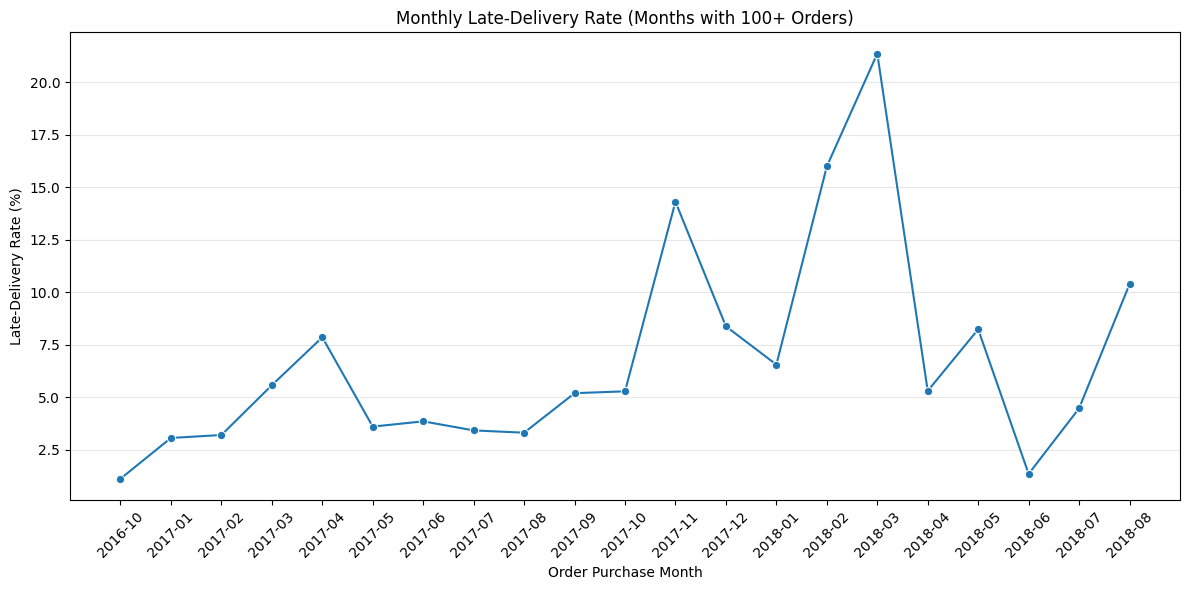

In [33]:
# Filter out months with fewer than 100 eligible orders
monthly_delivery_filtered = monthly_delivery[
    monthly_delivery["total_orders"] >= 100
].copy()

# Plot the monthly late-delivery rate
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_delivery_filtered,
    x="purchase_month",
    y="late_rate_pct",
    marker="o"
)

plt.title("Monthly Late-Delivery Rate (Months with 100+ Orders)")
plt.xlabel("Order Purchase Month")
plt.ylabel("Late-Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# 10. Key Findings and Business Recommendations

## Key Findings

**1. Overall Sales Performance**
- The platform recorded 99,441 orders, of which 96,478 were delivered.
- Product sales value associated with delivered orders was approximately R$13.22 million.

**2. Product Category Performance**
- Health & Beauty generated the highest product sales value among the analyzed categories, at approximately R$1.23 million.
- Watches & Gifts ranked second, with approximately R$1.17 million.
- Bed, Bath & Table had the highest item count among the top 10 categories.

**3. Delivery Performance**
- Average delivery time was 12.56 days, while the median was 10.22 days.
- Approximately 8.11% of eligible delivered orders arrived after their estimated delivery dates.

**4. Customer Satisfaction**
- Orders delivered late had an average review score of 2.57 out of 5.
- Orders delivered on time or early had an average review score of 4.29 out of 5.
- This difference indicates a strong association between delivery performance and customer satisfaction, but it does not establish causation.

**5. Regional and Monthly Patterns**
- Alagoas had the highest late-delivery rate among states with at least 100 eligible orders.
- São Paulo had the largest absolute number of late deliveries.
- March 2018 recorded a late-delivery rate of 21.36% among eligible orders purchased that month.

## Business Recommendations

1. **Investigate delivery delays:** Examine logistics and fulfillment records to understand why some orders arrive after their estimated delivery dates.

2. **Prioritize regional analysis:** Investigate states with high late-delivery rates and states contributing large numbers of late deliveries.

3. **Monitor delivery performance over time:** Track monthly late-delivery rates and order volumes to identify unusual changes.

4. **Improve the customer experience:** Investigate low-rated orders to understand whether delivery delays, product issues, or other factors contribute to dissatisfaction.

5. **Track measurable outcomes:** Monitor late-delivery rate, median delivery time, and average review score to evaluate whether future improvements are effective.

*Note: These findings describe observed patterns in the dataset. Further investigation is needed to establish underlying causes. Product sales value should not be interpreted as profit.*

In [34]:
# Summary of key business metrics

print("ECOMMERCE SALES & OPERATIONS INTELLIGENCE")
print("=" * 45)

print(f"Total orders: {orders['order_id'].nunique():,}")
print(f"Delivered orders: {orders.loc[orders['order_status'] == 'delivered', 'order_id'].nunique():,}")

print(f"\nProduct sales value (delivered orders): R${delivered_items['price'].sum():,.2f}")

print(f"\nAverage delivery time: {delivery_data['delivery_days'].mean():.2f} days")
print(f"Median delivery time: {delivery_data['delivery_days'].median():.2f} days")

print(f"\nLate-delivery rate: {(delay_data['delay_days'] > 0).mean() * 100:.2f}%")

print(f"\nAverage review score for late deliveries: {delivery_reviews.loc[delivery_reviews['delay_days'] > 0, 'review_score'].mean():.2f}/5")
print(f"Average review score for on-time/early deliveries: {delivery_reviews.loc[delivery_reviews['delay_days'] <= 0, 'review_score'].mean():.2f}/5")

ECOMMERCE SALES & OPERATIONS INTELLIGENCE
Total orders: 99,441
Delivered orders: 96,478

Product sales value (delivered orders): R$13,221,498.11

Average delivery time: 12.56 days
Median delivery time: 10.22 days

Late-delivery rate: 8.11%

Average review score for late deliveries: 2.57/5
Average review score for on-time/early deliveries: 4.29/5


# 11. Conclusion

This project analyzed the Brazilian E-Commerce Public Dataset by Olist to evaluate sales performance, product category contributions, delivery reliability, regional differences, and customer satisfaction.

The analysis revealed several important business insights:

- The platform recorded approximately R$13.22 million in product sales value associated with delivered orders.
- Health & Beauty was the leading product category by sales value, followed by Watches & Gifts.
- The average delivery time was 12.56 days, and 8.11% of eligible delivered orders arrived later than their estimated delivery dates.
- Orders delivered late had an average customer review score of 2.57 out of 5, compared with 4.29 for orders delivered on time or early.
- Late-delivery rates varied across Brazilian states and purchase months, highlighting areas that warrant further investigation.

These findings suggest that delivery reliability deserves particular attention because late deliveries were associated with substantially lower customer review scores. Regional and monthly patterns can also help guide more focused operational investigations.

Using Python, pandas, Matplotlib, and Seaborn, this project demonstrates how data analysis can turn raw e-commerce data into business insights and practical recommendations.

**Limitations:** The analysis identifies associations and patterns rather than proving causation. Product sales value is not profit, and further investigation would be required to determine the causes of delivery delays.